# Midterm : est-ce que le choc des prix de l'électricité de 2023 a accéléré le solaire sur les toits ?

Ce notebook part des fichiers publics bruts qui sont dans `data/` et arrive à tous les chiffres et graphiques de nos slides (d'où vient chaque fichier : voir le `README.md`). Il se lit de haut en bas, chaque section suit une étape de la consigne et dit à quelle slide elle correspond. Pour tout relancer : *Kernel → Restart & Run All* (moins d'une minute).

| Section | Étape de la consigne | Slides |
|---|---|---|
| 1. Les ingrédients : des fichiers bruts aux variables propres | 1-2. Variables, nettoyage | 2, 5, 6 |
| 2. Échantillon et statistiques descriptives | 2. Choisir l'échantillon | 6, 7 |
| 3. Analyse univariée (Y, Z, X) | 3. Goûter chaque ingrédient | 8 à 11 |
| 4. Analyse bivariée | 4. Les cuisiner ensemble | 12 à 14, backup |
| 5. Problèmes de causalité | 5. Goûter la recette | 15, 16 |

- **Y (ce qu'on explique)** : le nombre de nouvelles installations solaires par commune et par an.
- **X (la variable principale)** : la hausse du tarif d'électricité des ménages en 2023, en ct/kWh (« le choc »).
- **Z (hétérogénéité)** : la part de logements habités par leur propriétaire. En général un locataire ne peut pas poser de panneaux lui-même, donc on s'attend à ce que ça compte.

In [1]:
import json, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm                          # sert juste pour les intervalles de confiance de la section 4
from shapely import STRtree, points, get_parts        # pour savoir dans quelle commune tombe chaque installation
from shapely.geometry import shape
from shapely.ops import unary_union

BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#9aa5b1"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e5e8eb"})

## 1. Les ingrédients : des fichiers bruts aux variables propres (slides 5 et 6)

### 1a. Un seul numéro de commune pour toutes les sources
Premier problème : les communes suisses fusionnent quasiment chaque année, et chaque fichier utilise les numéros de commune de son année à lui. Le registre des mutations de l'OFS ([registre officiel des communes](https://www.bfs.admin.ch/bfs/de/home/grundlagen/agvch.html)) liste toutes les fusions depuis 2010 (ancien numéro → nouveau numéro). On suit ces liens jusqu'à la commune qui existe en 2026, comme ça **toutes les sources sont sur les communes de 2026**.

In [3]:
mutations = pd.read_csv("data/bfs_commune_mutations.csv")
mutations = mutations[mutations.InitialCode != mutations.TerminalCode]     # on garde que les vrais changements de numéro
successor = dict(zip(mutations.InitialCode, mutations.TerminalCode))

def to_2026(code):
    while code in successor:                   # on suit la chaîne de fusions : A -> B (2015) -> C (2021)
        code = successor[code]
    return code

print("exemple : la commune 343 est devenue", to_2026(343))

exemple : la commune 343 est devenue 329


### 1b. Population et canton (OFS STATPOP, [tableau px-x-0102010000_101](https://www.bfs.admin.ch/asset/de/px-x-0102010000_101))
Le fichier mélange une ligne par canton (`- Zürich`), par district (`>> ...`) et par commune (`......0001 Aeugst am Albis`), pour chaque année. On ne garde que les lignes de communes, en retenant au passage dans quel canton on est.

In [5]:
raw = pd.read_csv("data/bfs_population.csv", encoding="latin1")
raw.columns = ["year", "place", "type", "nationality", "sex", "pop"]
rows, canton = [], None
for place, year, n in zip(raw.place, raw.year, raw["pop"]):
    if place.startswith("- "):
        canton = place[2:]                                          # ligne de canton : on le retient
    elif place.startswith("......"):
        rows.append((to_2026(int(place[6:10])), canton, year, n))   # ligne de commune
pop = pd.DataFrame(rows, columns=["bfs", "canton", "year", "pop"])
canton_of = pop.groupby("bfs").canton.last()
pop = pop.groupby(["bfs", "year"])["pop"].sum().unstack()          # communes fusionnées additionnées, une colonne par année
print("communes en 2026 :", len(pop))

communes en 2026 : 2110


### 1c. X : la hausse du tarif en 2023 (ElCom, [prix de l'électricité par gestionnaire de réseau](https://opendata.swiss/de/dataset/strompreis-per-stromnetzbetreiber))
Il y a un tarif par commune × gestionnaire × année et par profil de consommation. On prend le profil **H4** (le ménage type de l'ElCom : un 5 pièces, 4 500 kWh/an), le **prix total** en ct/kWh, on fait la moyenne sur les gestionnaires qui desservent la commune, et on calcule **X = 2023 − 2022**. Les tarifs 2023 ont été publiés en août 2022. On garde aussi le gestionnaire principal de chaque commune : celui qui apparaît le plus souvent en 2023 (en cas d'égalité, le plus petit numéro ElCom).

In [7]:
elcom = pd.read_csv("data/elcom_tariffs_H2_H4_H7.csv")
h4 = elcom[elcom.category == "H4"].copy()
h4["bfs"] = h4.municipality.map(to_2026)
tariff = h4.groupby(["bfs", "period"]).total.mean().unstack()          # une colonne par année, en ct/kWh
energy = h4.groupby(["bfs", "period"]).energy.mean().unstack()         # la partie "énergie" du prix
main_operator = h4[h4.period == 2023].groupby("bfs").operator.agg(lambda s: s.mode().iloc[0])
tariff[[2021, 2022, 2023]].head(3)

period,2021,2022,2023
bfs,,,
1,17.122,17.084,21.878
2,17.122,17.084,21.878
3,17.122,17.084,21.878


### 1d. Z : part de propriétaires occupants (recensement 2000 de l'OFS, [tableau px-x-0903020000_103](https://www.bfs.admin.ch/asset/de/px-x-0903020000_103))
Les logements par type d'occupant et par nombre de pièces, pour chaque commune. Propriétaires = propriétaires par étage (PPE) + propriétaires seuls de la maison + copropriétaires. Z = propriétaires ÷ tous les logements occupés. Comme le registre des fusions commence en 2010, les communes fusionnées avant ne peuvent pas être retrouvées : pour elles Z manque.

In [9]:
census = pd.read_csv("data/bfs_dwellings_by_occupant_2000_all.csv")
census = census[census.Gemeinde.str.match(r"^\d{4} ")].copy()                 # lignes de communes : "0001 Aeugst am Albis"
census["bfs"] = census.Gemeinde.str[:4].astype(int).map(to_2026)
occupants = [c for c in census.columns if c not in ("Gemeinde", "Anzahl Zimmer", "bfs")]
census = census.groupby("bfs")[occupants].sum()                                # on additionne les tailles de logement et les fusions
owners = census[["Stockwerk-/Wohnungseigentümer/in", "Alleineigentümer/in des Hauses", "Miteigentümer/in des Hauses"]].sum(axis=1)
owner_share = owners / census.sum(axis=1)

### 1e. Y : les nouvelles installations solaires (OFEN, [registre des installations de production d'électricité](https://opendata.swiss/de/dataset/elektrizitatsproduktionsanlagen), extrait du 14 sept. 2026)
Toutes les installations de production d'électricité en Suisse avec leur type, leur date de mise en service, leur puissance et leur position. On garde le **photovoltaïque** et l'**année de mise en service** (attention, c'est le raccordement au réseau, pas la décision d'acheter).

Chaque installation est placée dans une commune en deux étapes :
1. **Les coordonnées** : le registre donne des coordonnées suisses (LV95). On les convertit en longitude/latitude avec la formule approchée de swisstopo, puis on regarde quel polygone de commune ([swisstopo swissBOUNDARIES3D](https://www.swisstopo.admin.ch/de/landschaftsmodell-swissboundaries3d), version 2020) contient le point.
2. **Le code postal**, pour les quelques installations sans coordonnées : l'[annuaire des localités](https://www.swisstopo.admin.ch/de/amtliches-ortschaftenverzeichnis) de swisstopo donne la commune qui a le plus d'adresses dans ce code postal.

In [11]:
with zipfile.ZipFile("data/bfe_plants.csv.zip") as z:
    plants = pd.read_csv(z.open("ElectricityProductionPlant.csv"), encoding="utf-8-sig", dtype={"PostCode": str})
pv = plants[plants.SubCategory == "subcat_2"].copy()                    # subcat_2 = photovoltaïque
pv["year"] = pd.to_datetime(pv.BeginningOfOperation, errors="coerce").dt.year
pv["kw"] = pv.InitialPower
print(f"installations PV dans le registre : {len(pv):,}")

# les polygones des communes, regroupés en communes 2026
with open("data/swiss_boundaries_2020.geojson", encoding="utf-8") as f:
    features = [ft for ft in json.load(f)["features"] if ft["properties"].get("OBJEKTART") == "Gemeindegebiet"]
polygons = pd.DataFrame({"bfs": [to_2026(int(ft["properties"]["BFS_NUMMER"])) for ft in features],
                         "geom": [shape(ft["geometry"]) for ft in features]})
polygons = polygons.groupby("bfs").geom.apply(lambda g: unary_union(list(g)))

installations PV dans le registre : 337,455


In [12]:
# étape 1 : les coordonnées. LV95 -> longitude/latitude (formule approchée de swisstopo), puis on cherche le polygone qui contient le point
E, N = (pv._x - 2600000) / 1e6, (pv._y - 1200000) / 1e6
lon = (2.6779094 + 4.728982 * E + 0.791484 * E * N + 0.1306 * E * N**2 - 0.0436 * E**3) * 100 / 36
lat = (16.9023892 + 3.238272 * N - 0.270978 * E**2 - 0.002528 * N**2 - 0.0447 * E**2 * N - 0.0140 * N**3) * 100 / 36
plant_nr, commune_nr = STRtree(polygons.values).query(points(lon, lat), predicate="within")
pv["bfs"] = pd.Series(polygons.index[commune_nr], index=pv.index[plant_nr])   # celles sans coordonnées restent vides pour l'instant
print(f"placées grâce aux coordonnées : {pv.bfs.notna().mean():.1%}")

placées grâce aux coordonnées : 99.3%


In [13]:
# étape 2 : le code postal, pour celles qui n'ont pas de coordonnées. L'annuaire de swisstopo donne pour chaque
# code postal les communes concernées et leur part d'adresses ; on prend la commune avec la plus grosse part
with zipfile.ZipFile("data/ortschaftenverzeichnis_plz.csv.zip") as z:
    postcodes = pd.read_csv(z.open("AMTOVZ_CSV_LV95/AMTOVZ_CSV_LV95.csv"), sep=";", encoding="utf-8-sig", dtype={"PLZ4": str})
postcodes["share"] = postcodes.Adressenanteil.str.replace("%", "").astype(float)
main_commune = postcodes.sort_values("share").drop_duplicates("PLZ4", keep="last").set_index("PLZ4")["BFS-Nr"]
pv["bfs"] = pv.bfs.fillna(pv.PostCode.map(main_commune).map(to_2026, na_action="ignore"))
print(f"placées au total : {pv.bfs.notna().mean():.1%}")

placées au total : 100.0%


### 1f. Contrôle : les maisons individuelles (statistique des bâtiments de l'OFS, [GWS par commune](https://stats.swiss/vis?df[ds]=disseminate&df[id]=DF_GWS_REG1&df[ag]=CH1.GWS&df[vs]=1.0.0&lc=de), 2021)
On s'en sert seulement pour discuter Z : la part des bâtiments d'habitation qui sont des maisons individuelles.

In [15]:
buildings = pd.read_csv("data/bfs_gws_buildings_2015_2024.csv")
buildings = buildings[(buildings.TIME_PERIOD == 2021) & buildings.GEMEINDENAME.astype(str).str.fullmatch(r"\d+")].copy()
buildings["bfs"] = buildings.GEMEINDENAME.astype(int).map(to_2026)
buildings = buildings.groupby(["bfs", buildings.GKATS.astype(str)]).OBS_VALUE.sum().unstack()
sfh_share = buildings["1021"] / buildings["_T"]                          # 1021 = maison individuelle, _T = tous les bâtiments

### 1g. L'échantillon et les deux tableaux avec lesquels on travaille
Échantillon = les communes qui ont une population et un tarif 2022 et 2023, sur les années **2015 à 2025** (2026 est incomplète, l'extrait du registre date de septembre 2026).
- `communes` : une ligne par commune (X, Z, contrôles) ; `tariff` : le tarif H4 de chaque commune de l'échantillon, par année.
- `installs` : une ligne par commune et par année (Y).

In [17]:
sample = sorted(set(pop.index) & set(tariff.index[tariff[2022].notna() & tariff[2023].notna()]))
missing = sorted(set(pop.index) - set(sample))
print(f"échantillon : {len(sample):,} communes sur {len(pop):,} ; sans tarif 2022 :", canton_of[missing].value_counts().to_dict())

communes = pd.DataFrame(index=pd.Index(sample, name="bfs"))
communes["canton"] = canton_of
communes["operator"] = main_operator
communes["regional_utility"] = communes.operator.map(communes.operator.value_counts()) >= 10   # gestionnaire principal de 10 communes ou plus
communes["pop_2021"] = pop[2021]
communes["shock23"] = tariff[2023] - tariff[2022]                     # X
communes["shock_energy23"] = energy[2023] - energy[2022]
communes["t2022"] = tariff[2022]
communes["owner_share_2000"] = owner_share                            # Z
communes["sfh_share_2021"] = sfh_share
communes["pv_stock21_pc"] = pv[pv.year <= 2021].groupby("bfs").size().reindex(sample, fill_value=0) / communes.pop_2021 * 1000
tariff = tariff.loc[sample, 2015:2027]

located = pv[pv.bfs.isin(sample) & pv.year.between(2015, 2025)]
grid = pd.MultiIndex.from_product([sample, range(2015, 2026)], names=["bfs", "year"])
installs = located.groupby(["bfs", "year"]).agg(n_new=("kw", "size"), kw_new=("kw", "sum")).reindex(grid, fill_value=0).reset_index()   # 0 si aucune installation cette année-là

print(f"installations 2015-2025 dans l'échantillon : {installs.n_new.sum():,} ; plus de 30 kW : {(located.kw > 30).mean():.0%}")
print(f"{len(installs):,} communes-années ; {communes.operator.nunique()} gestionnaires principaux ; communes sans Z : {communes.owner_share_2000.isna().sum()}")

échantillon : 2,098 communes sur 2,110 ; sans tarif 2022 : {'Graubünden / Grigioni / Grischun': 8, 'Aargau': 2, 'Fribourg / Freiburg': 1, 'Vaud': 1}


installations 2015-2025 dans l'échantillon : 297,633 ; plus de 30 kW : 12%
23,078 communes-années ; 495 gestionnaires principaux ; communes sans Z : 35


## 2. Échantillon et statistiques descriptives (slides 6 et 7)

Une ligne par commune. On résume Y par le nombre moyen de nouvelles installations **par an** avant (2017-21) et après (2023-24) le choc. 2022 n'est dans aucune des deux périodes : le choc a été annoncé en août 2022, donc c'est une année à moitié avant, à moitié après.
**Croissance** = log(1 + installations par an 2023-24) − log(1 + installations par an 2017-21). Le log rend une ville et un village comparables (on regarde une croissance relative, pas des nombres bruts), et le « 1 + » sert aux communes qui ont zéro installation. C'est ce Y-là qu'on utilise dans la section 4.

In [19]:
communes["n_pre"] = installs[installs.year.between(2017, 2021)].groupby("bfs").n_new.mean()
communes["n_post"] = installs[installs.year.isin([2023, 2024])].groupby("bfs").n_new.mean()
communes["growth"] = np.log1p(communes.n_post) - np.log1p(communes.n_pre)

summary = communes[["n_pre", "n_post", "growth", "shock23", "owner_share_2000"]].describe().T
summary[["count", "mean", "std", "min", "50%", "max"]].round(2)          # le tableau de la slide 7

,count,mean,std,min,50%,max
n_pre,2098.0,7.97,9.77,0.00,5.20,112.80
n_post,2098.0,28.44,33.54,0.00,18.50,484.00
growth,2098.0,1.10,0.44,-0.82,1.13,2.41
shock23,2098.0,6.58,5.01,-0.47,5.06,43.00
owner_share_2000,2063.0,0.54,0.15,0.04,0.56,0.96


## 3. Analyse univariée

### Y et Z (slides 8, 9 et 10)
- **Y** est un **comptage** : dans le temps il monte doucement, saute en 2023 et retombe en 2025 ; entre communes il est très **asymétrique** (la plupart des communes ajoutent une poignée d'installations par an, quelques villes en ajoutent des centaines). Donc on compare des **taux de croissance et des indices**, jamais des niveaux bruts.
- **Z** est une **part** (entre 0 et 1), fixe dans le temps (un seul recensement, 2000), bien étalée autour de sa médiane de 56 %. On coupe les communes à la médiane dans la section 4. Limites : la donnée est vieille, et c'est une moyenne pour toute la commune.

installations 2021 -> 2023 : 23,291 -> 61,682 (+165%)


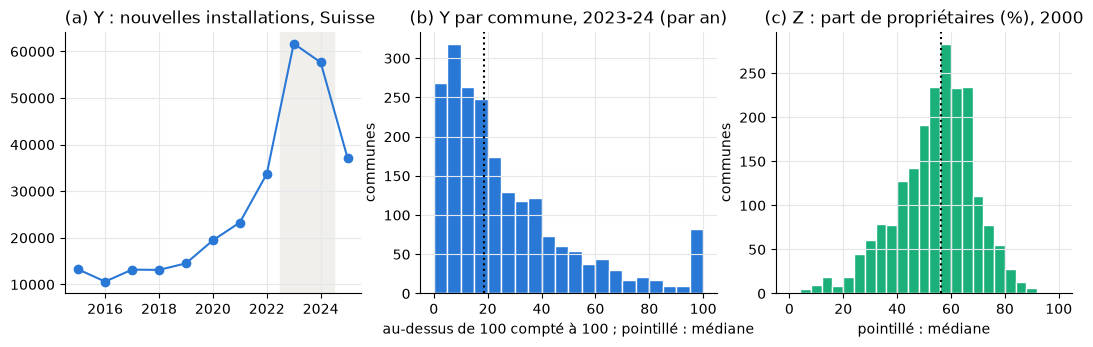

In [21]:
per_year = installs.groupby("year").n_new.sum()
print(f"installations 2021 -> 2023 : {per_year[2021]:,} -> {per_year[2023]:,} ({per_year[2023] / per_year[2021] - 1:+.0%})")

fig, axs = plt.subplots(1, 3, figsize=(13, 3.4))
axs[0].plot(per_year.index, per_year, marker="o", color=BLUE)
axs[0].axvspan(2022.5, 2024.5, color="#f0efec", zorder=0)               # en gris : 2023-24
axs[0].set_title("(a) Y : nouvelles installations, Suisse", loc="left")
axs[1].hist(communes.n_post.clip(upper=100), bins=range(0, 105, 5), color=BLUE, edgecolor="white")
axs[1].axvline(communes.n_post.median(), color="black", ls=":")
axs[1].set(title="(b) Y par commune, 2023-24 (par an)", xlabel="au-dessus de 100 compté à 100 ; pointillé : médiane", ylabel="communes")
axs[2].hist(communes.owner_share_2000 * 100, bins=range(0, 101, 4), color=GREEN, edgecolor="white")
axs[2].axvline(communes.owner_share_2000.median() * 100, color="black", ls=":")
axs[2].set(title="(c) Z : part de propriétaires (%), 2000", xlabel="pointillé : médiane", ylabel="communes")
plt.show()

Et dans l'espace : où est-ce que les installations ont augmenté, et où habitent les propriétaires ? Chaque carte colorie les communes par classe ; en gris, pas de donnée.

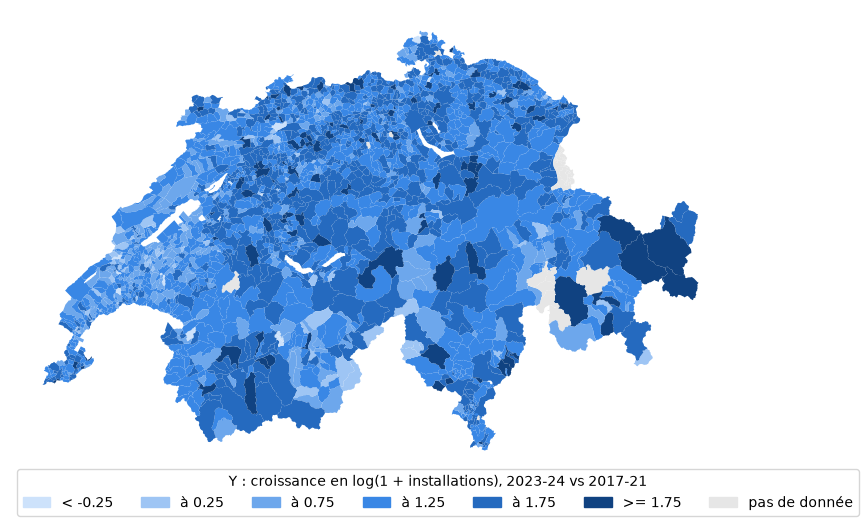

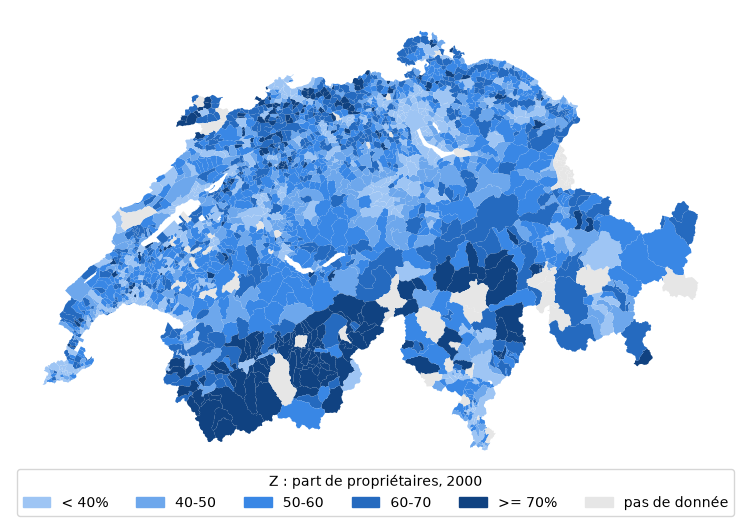

In [23]:
def draw_map(values, edges, labels, title):
    # colorie chaque commune selon la classe de sa valeur (edges = limites des classes) ; frontières simplifiées pour aller plus vite
    colours = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#104281"][-len(labels):]
    fig, ax = plt.subplots(figsize=(10, 6))
    for bfs, geom in polygons.items():
        value = values.get(bfs)
        colour = "#e6e6e6" if pd.isna(value) else colours[np.digitize(value, edges)]
        for part in get_parts(geom.simplify(0.001)):
            ax.fill(*part.exterior.xy, color=colour, linewidth=0)
    ax.set_aspect(1.46); ax.axis("off")                                  # 1.46 = 1 / cos(latitude de la Suisse), sinon la carte est écrasée
    ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in colours + ["#e6e6e6"]], labels + ["pas de donnée"],
              title=title, ncol=len(labels) + 1, loc="upper left", bbox_to_anchor=(0, 0.02))
    plt.show()

draw_map(communes.growth, [-0.25, 0.25, 0.75, 1.25, 1.75], ["< -0.25", "à 0.25", "à 0.75", "à 1.25", "à 1.75", ">= 1.75"],
         "Y : croissance en log(1 + installations), 2023-24 vs 2017-21")
draw_map(communes.owner_share_2000, [0.4, 0.5, 0.6, 0.7], ["< 40%", "40-50", "50-60", "60-70", ">= 70%"], "Z : part de propriétaires, 2000")

### X, la hausse du tarif en 2023 (slides 2 et 11)
Nature : **continue** (ct/kWh). Pas de log : quelques communes ont même eu une petite baisse, et on ne peut pas prendre le log d'un nombre négatif. Les 17 communes au-dessus de 25 ct sont réelles (des petits distributeurs locaux) : on les garde au lieu de les supprimer comme valeurs extrêmes.

In [25]:
print(communes.shock23.describe().round(2))
print(f"hausse médiane par rapport au tarif 2022 : {(communes.shock23 / communes.t2022).median():+.0%}")      # slide 2
print(f"part énergie de la hausse (sur les moyennes) : {communes.shock_energy23.mean() / communes.shock23.mean():.0%}")
within = communes.shock23 - communes.groupby("canton").shock23.transform("mean")   # on enlève la moyenne de chaque canton
print(f"part de la variance à l'intérieur des cantons : {within.var() / communes.shock23.var():.0%}")
print("communes au-dessus de 25 ct :", (communes.shock23 > 25).sum())

count    2098.00
mean        6.58
std         5.01
min        -0.47
25%         3.80
50%         5.06
75%         9.85
max        43.00
Name: shock23, dtype: float64
hausse médiane par rapport au tarif 2022 : +28%
part énergie de la hausse (sur les moyennes) : 87%
part de la variance à l'intérieur des cantons : 74%
communes au-dessus de 25 ct : 17


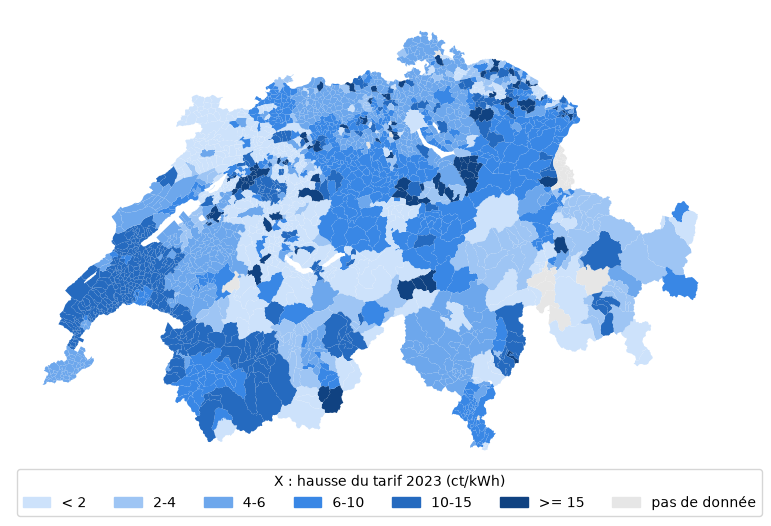

In [26]:
draw_map(communes.shock23, [2, 4, 6, 10, 15], ["< 2", "2-4", "4-6", "6-10", "10-15", ">= 15"], "X : hausse du tarif 2023 (ct/kWh)")

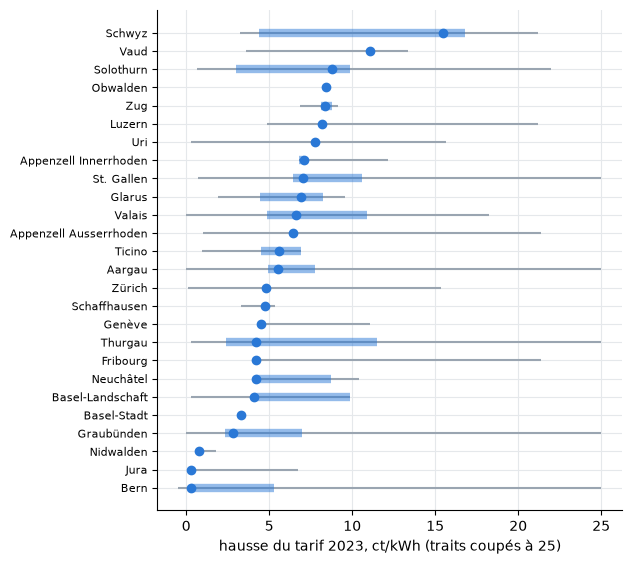

In [27]:
# dispersion dans chaque canton : trait = du min au max, barre épaisse = les 50 % du milieu, point = médiane
stats = communes.groupby("canton").shock23.describe().sort_values("50%")
rows = range(len(stats))
fig, ax = plt.subplots(figsize=(6, 6.5))
ax.hlines(rows, stats["min"], stats["max"].clip(upper=25), color=GREY)
ax.hlines(rows, stats["25%"], stats["75%"], color=BLUE, lw=6, alpha=.5)
ax.plot(stats["50%"], rows, "o", color=BLUE)
ax.set_yticks(rows, [name.split(" / ")[0] for name in stats.index], fontsize=8)
ax.set_xlabel("hausse du tarif 2023, ct/kWh (traits coupés à 25)")
plt.show()

## 4. Analyse bivariée

### Les tiers du choc (slide 12)
On coupe les communes en trois groupes de taille à peu près égale selon X (les communes avec exactement la même valeur restent ensemble) et on suit Y dans le temps. Y est **additionné sur les communes de chaque groupe** (donc les grosses communes pèsent plus) et **ramené à 2021 = 100**, parce que les groupes n'ont pas la même taille.

hausse moyenne par tiers : {'low': 2.0, 'middle': 5.9, 'high': 12.3}


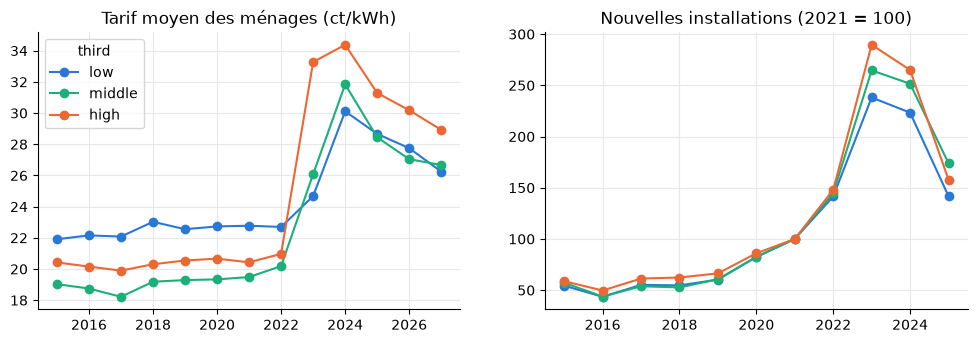

indice 2023 : {'low': 238.0, 'middle': 265.0, 'high': 290.0}
écart de tarif high - low : 8.6 ct (2023) -> 4.3 ct (2024)
hausse du tarif 2023 -> 2024 : {'low': 5.4, 'middle': 5.8, 'high': 1.1}


In [29]:
communes["third"] = pd.qcut(communes.shock23, 3, labels=["low", "middle", "high"])
print("hausse moyenne par tiers :", communes.groupby("third", observed=True).shock23.mean().round(1).to_dict())

tariff_by_third = tariff.groupby(communes.third, observed=True).mean().T
counts = installs.join(communes.third, on="bfs").groupby(["year", "third"], observed=True).n_new.sum().unstack()
index = counts / counts.loc[2021] * 100                                  # chaque groupe divisé par son propre total 2021

fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
tariff_by_third.plot(ax=axs[0], marker="o", color=[BLUE, GREEN, ORANGE], title="Tarif moyen des ménages (ct/kWh)", xlabel="")
index.plot(ax=axs[1], marker="o", color=[BLUE, GREEN, ORANGE], title="Nouvelles installations (2021 = 100)", legend=False, xlabel="")
plt.show()

print("indice 2023 :", index.loc[2023].round().to_dict())
gap = tariff_by_third["high"] - tariff_by_third["low"]
print(f"écart de tarif high - low : {gap[2023]:.1f} ct (2023) -> {gap[2024]:.1f} ct (2024)")
print("hausse du tarif 2023 -> 2024 :", (tariff_by_third.loc[2024] - tariff_by_third.loc[2023]).round(1).to_dict())   # les autres rattrapent en partie

Avant 2022 les lignes bougent à peu près ensemble ; en 2023 c'est le tiers à fort choc qui grandit le plus ; en 2024 les deux autres tiers rattrapent une partie de la hausse de tarif (l'écart est divisé par deux), et en 2025 l'écart d'installations se resserre.

### Commune par commune (slide 13)
X reste continue ; Y, c'est la croissance définie dans la section 2.
Pour comparer ce qui est comparable, on enlève la moyenne du canton à X et à la croissance (les cantons ont leurs propres règles et subventions), puis on fait passer une droite.

pente : 0.24 log points de croissance par +10 ct/kWh, à l'intérieur des cantons


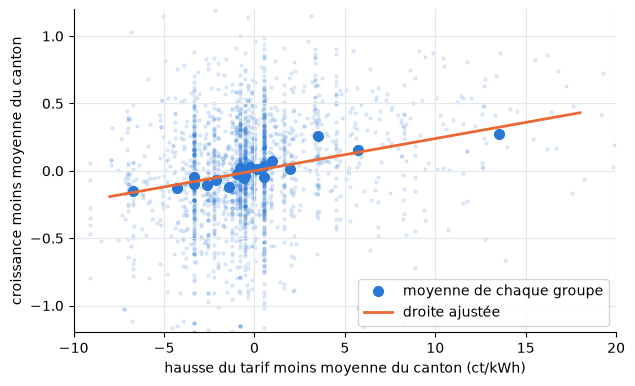

In [31]:
x = communes.shock23 - communes.groupby("canton").shock23.transform("mean")      # X moins la moyenne du canton
y = communes.growth - communes.groupby("canton").growth.transform("mean")         # croissance moins la moyenne du canton

slope = np.polyfit(x, y, 1)[0]                                            # pente de la droite
print(f"pente : {slope * 10:.2f} log points de croissance par +10 ct/kWh, à l'intérieur des cantons")

groups = pd.qcut(x.rank(method="first"), 20, labels=False)               # 20 groupes de communes de même taille selon x
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.scatter(x, y, s=5, alpha=.12, color=BLUE)
ax.plot(x.groupby(groups).mean(), y.groupby(groups).mean(), "o", color=BLUE, ms=7, label="moyenne de chaque groupe")
ax.plot([-8, 18], [-8 * slope, 18 * slope], color=ORANGE, lw=2, label="droite ajustée")
ax.set(xlim=(-10, 20), ylim=(-1.2, 1.2), xlabel="hausse du tarif moins moyenne du canton (ct/kWh)", ylabel="croissance moins moyenne du canton")
ax.legend(); plt.show()

**Vérification avant le choc, et précision des pentes (slide 13).** La même pente calculée sur la croissance de 2017-18 à 2020-21 (quand personne ne savait encore pour 2023) devrait être à peu près nulle : c'est notre test placebo. Pour l'intervalle de confiance à 95 %, on refait la même droite avec une vraie régression, en laissant les communes d'un même gestionnaire partager leurs erreurs (elles ont reçu le même choc, donc elles ne sont pas indépendantes).

In [33]:
before = installs[installs.year.isin([2020, 2021])].groupby("bfs").n_new.mean()
earlier = installs[installs.year.isin([2017, 2018])].groupby("bfs").n_new.mean()
placebo = np.log1p(before) - np.log1p(earlier)
y_placebo = placebo - placebo.groupby(communes.canton).transform("mean")

for name, outcome in [("après le choc (2023-24)", y), ("avant le choc (2020-21)", y_placebo)]:
    fit = sm.OLS(outcome, sm.add_constant(x / 10)).fit(cov_type="cluster", cov_kwds={"groups": communes.operator})
    low, high = fit.conf_int().loc["shock23"]
    print(f"{name} : pente {fit.params['shock23']:.2f}, IC 95% {low:.2f} à {high:.2f}")

après le choc (2023-24) : pente 0.24, IC 95% 0.20 à 0.28
avant le choc (2020-21) : pente 0.02, IC 95% -0.03 à 0.07


### Avec Z (slide 14)
Les mêmes tiers, mais séparément pour les communes en dessous et au-dessus de la médiane de propriétaires (56 %). C'est seulement descriptif : Z bouge aussi avec le type de logement et la taille de la commune (voir le tableau d'après).

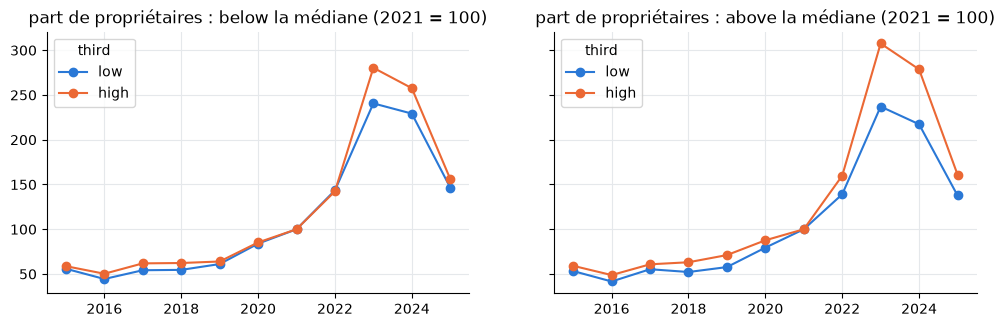

third,low,high
z_group,,
below,241.0,280.0
above,237.0,308.0


In [35]:
median = communes.owner_share_2000.median()
communes["z_group"] = pd.cut(communes.owner_share_2000, [0, median, 1], right=False, labels=["below", "above"])
counts = installs.join(communes[["third", "z_group"]], on="bfs").groupby(["year", "z_group", "third"], observed=True).n_new.sum()
index_z = (counts / counts.xs(2021, level="year") * 100).unstack(["z_group", "third"])

fig, axs = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, group in zip(axs, ["below", "above"]):
    index_z[group][["low", "high"]].plot(ax=ax, marker="o", color=[BLUE, ORANGE], title=f"part de propriétaires : {group} la médiane (2021 = 100)", xlabel="")
plt.show()
index_z.loc[2023].unstack()[["low", "high"]].round()                   # indice 2023, choc fort contre faible

### Qu'est-ce qui bouge avec X, Y et Z ? (slide backup ; chiffres utilisés sur les slides 10, 14 et 16)

In [37]:
communes["log_pop"] = np.log(communes.pop_2021)
names = {"shock23": "X : choc", "growth": "Y : croissance", "owner_share_2000": "Z : propriétaires", "t2022": "tarif 2022",
         "sfh_share_2021": "part maisons individuelles", "pv_stock21_pc": "PV pour 1000 hab. 2021", "log_pop": "log population"}
communes[list(names)].rename(columns=names).corr()[["X : choc", "Y : croissance", "Z : propriétaires"]].round(2)

,X : choc,Y : croissance,Z : propriétaires
X : choc,1.00,0.14,-0.05
Y : croissance,0.14,1.00,-0.13
Z : propriétaires,-0.05,-0.13,1.00
tarif 2022,-0.26,-0.07,-0.00
part maisons individuelles,0.05,0.08,0.41
PV pour 1000 hab. 2021,0.03,-0.47,0.40
log population,0.08,0.43,-0.62


## 5. Problèmes de causalité (slides 15 et 16)

**Est-ce qu'il y a autre chose ?** Le choc n'est pas aléatoire, ce sont les gestionnaires qui l'ont choisi. Le même gestionnaire fixe aussi le **tarif de reprise** (ce qu'il paie pour le courant solaire injecté dans le réseau). Les tarifs de reprise viennent de VESE ([pvtarif](https://www.pvtarif.ch), sous licence, réservé au groupe) : rétribution = énergie + garantie d'origine, pour les petites installations. On compare 2021 et 2023, parce qu'en 2022 les gestionnaires qui suivent le prix du marché trimestriel n'ont qu'une photo d'un seul trimestre.

*Données des tarifs de rétribution : VESE / pvtarif.ch (http://www.vese.ch, http://www.pvtarif.ch).*

In [39]:
print(communes.groupby("regional_utility").shock23.mean().round(1))      # True = gestionnaire principal de 10 communes ou plus

def feed_in(year):
    with open(f"data/vese_pvtarif_{year}.json", encoding="utf-8") as f:
        vese = pd.DataFrame.from_dict(json.load(f), orient="index")       # une ligne par gestionnaire
    energy = pd.to_numeric(vese.energy1, errors="coerce")
    origin = pd.to_numeric(vese.eco1, errors="coerce").fillna(0).where(vese.ecoIncl != "y", 0)   # sauf si elle est déjà incluse
    return (energy + origin).where(energy > 0).rename(int)               # 0 = case pas remplie

feedin_change = communes.operator.map(feed_in(2023)) - communes.operator.map(feed_in(2021))
ok = feedin_change.notna()
print(f"X contre hausse du tarif de reprise 2021->2023 : r = {communes.shock23[ok].corr(feedin_change[ok]):.2f} ({ok.sum():,} communes)")

regional_utility
False    8.5
True     5.8
Name: shock23, dtype: float64
X contre hausse du tarif de reprise 2021->2023 : r = 0.79 (1,994 communes)


- **Les gestionnaires ont choisi le choc.** Les gros distributeurs (gestionnaire principal de 10 communes ou plus) et les communes qui avaient déjà un tarif 2022 élevé (r = −0,26, section 4) ont eu des hausses **plus petites**.
- **Le tarif de reprise a bougé aussi.** Il a bougé avec X (r = 0,79) : deux explications possibles qu'il faudra séparer.
- **Tout le monde a été touché.** Toutes les communes ont vécu la crise, et les communes à faible choc ont rattrapé en partie en 2024 (l'écart de tarif est divisé par deux, section 4). Ce qu'on voit, c'est donc une différence de court terme entre communes.
- **Politique locale et offre.** Les subventions communales et les files d'attente des installateurs peuvent varier d'une commune à l'autre ; on ne les observe pas encore.
- **Le timing.** Au-dessus de la médiane de propriétaires, le tiers à fort choc était déjà devant en 2022 (section 4) : peut-être de l'anticipation, vu que les tarifs 2023 étaient connus dès août 2022.

**Est-ce que c'est l'inverse ?** Peu probable : les tarifs 2023 ont été publiés fin août 2022, avant les installations qu'on compte. Plus de solaire pourrait faire monter les frais de réseau, mais 87 % de la hausse vient de la partie énergie (section 3), et X n'a aucun lien avec le solaire qu'une commune avait déjà (r = 0,03).

**Est-ce qu'on peut généraliser ?** Seulement avec prudence : une seule année de crise très médiatisée ; des moyennes par commune, pas des propriétaires individuels (Z est une part au niveau de la commune) ; Y compte toutes les installations (12 % font plus de 30 kW : fermes, entreprises) ; biais d'échantillon : 12 communes sans tarif 2022 sont exclues (dont 8 aux Grisons) et Z manque pour 35.

**Plan pour le final :** comparer les communes à l'intérieur des cantons dans le temps avec une régression, tester les tendances avant le choc et l'anticipation, comparer des communes voisines avec des gestionnaires différents, utiliser Z en continu, et essayer de séparer la hausse du tarif de détail de celle du tarif de reprise.